<a href="https://colab.research.google.com/github/jesuscarpio5/Analisis-deportivo/blob/main/01_primer_analisis_statsbomb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mplsoccer statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


In [2]:
from statsbombpy import sb
import warnings
warnings.filterwarnings("ignore")

# Competiciones disponibles en abierto
comps = sb.competitions()
comps[["competition_id","season_id","competition_name","season_name"]].head(30)

,competition_id,season_id,competition_name,season_name
0,9,281,1. Bundesliga,2023/2024
1,9,27,1. Bundesliga,2015/2016
2,1267,107,African Cup of Nations,2023
3,16,4,Champions League,2018/2019
4,16,1,Champions League,2017/2018
5,16,2,Champions League,2016/2017
6,16,27,Champions League,2015/2016
7,16,26,Champions League,2014/2015
8,16,25,Champions League,2013/2014
9,16,24,Champions League,2012/2013


   match_id home_team     away_team  home_score  away_score
0      8650    Brazil       Belgium           1           2
1      7584   Belgium         Japan           3           2
2      7554   England        Panama           6           1
3      7539    Poland       Senegal           1           2
4      7550    Serbia   Switzerland           1           2
5      7538    Sweden   South Korea           1           0
6      7534   Germany        Mexico           0           1
7      7543      Iran         Spain           0           1
8      7544   Uruguay  Saudi Arabia           1           0
9      7546    France          Peru           1           0


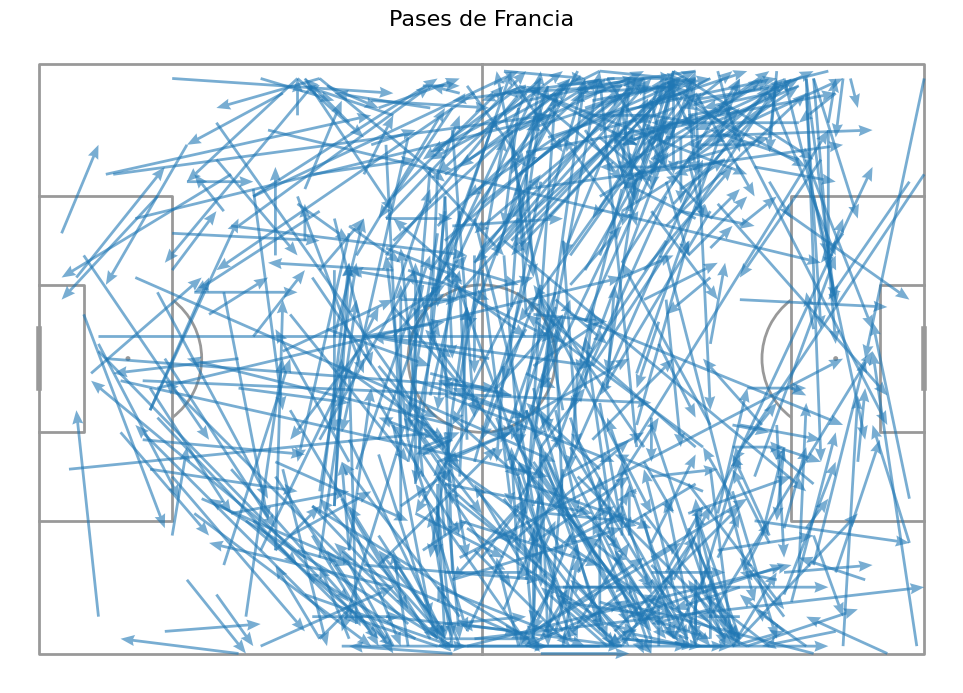

In [3]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

partidos = sb.matches(competition_id=43, season_id=3)
print(partidos[["match_id","home_team","away_team","home_score","away_score"]].head(10))

# Final: Francia - Croacia
match_id = partidos[(partidos.home_team=="France") | (partidos.away_team=="France")].iloc[-1].match_id
eventos = sb.events(match_id=match_id)

pases = eventos[(eventos.type=="Pass") & (eventos.team=="France")]

pitch = Pitch(pitch_type="statsbomb", line_color="#999999")
fig, ax = pitch.draw(figsize=(10,7))
pitch.arrows(pases.location.str[0], pases.location.str[1],
             pases.pass_end_location.str[0], pases.pass_end_location.str[1],
             ax=ax, width=2, headwidth=4, color="#1f77b4", alpha=0.6)
ax.set_title("Pases de Francia", fontsize=16)
plt.show()